# Speckle2Self — Training Curves
Parses the epoch-level summaries from the final training run (`260720-cropped4`, 200 epochs).
Plots Train/Val for total loss, reconstruction loss, and consistency loss.

## Loss Guide

Speckle2Self is self-supervised: it never sees a clean ground-truth image. Instead the network receives the same noisy image downsampled to three resolutions (high, mid, low), produces a denoised output for each, and is trained with two complementary objectives.

### Reconstruction loss (L2 / MSE)
Each output must reconstruct **its own noisy input**. Using the noisy image as the reconstruction target is the self-supervised trick — because speckle is a multiplicative, signal-dependent noise with specific statistical properties, the network learns to suppress it rather than memorise the input. Applied independently to all three resolution branches with equal weight (1.0 each). Lower is better.

### Consistency loss (L1)
The three outputs — produced from the same underlying anatomy but at different scales — must **agree with each other**. This acts as a regulariser: a network that overfits to noise at one scale will be penalised by the other two. Applied to all three pairs (H↔L, H↔M, M↔L) with equal weight (1.0 each). Lower is better.

### Total loss
Plain sum of all six terms: `total = rec(H) + rec(M) + rec(L) + consist(H,L) + consist(H,M) + consist(M,L)`. Each individual term is already a pixel-level mean (MSE or L1), so total loss is a sum of six pixel-averaged quantities. The per-epoch value plotted here is then the mean of that over all batches.

In [15]:
import re
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from IPython.display import display as ipy_display, Image as IPyImage
import os

LOG_PATH = r"D:\dissertation-results\speckle2self-results\260720-cropped4\train_260720-015018.log"
OUT_DIR  = os.getcwd()

In [16]:
# ── Parse epoch summaries ─────────────────────────────────────────────────────
epochs, train_total, train_rec, train_consist = [], [], [], []
val_total, val_rec, val_consist = [], [], []

with open(LOG_PATH, encoding='utf-8') as f:
    text = f.read()

# Split on epoch boundaries
blocks = re.split(r'(?=\[EPOCH \d+/\d+\] Started)', text)
for block in blocks:
    epoch_m = re.search(r'\[EPOCH (\d+)/\d+\] Completed', block)
    train_m = re.search(r'Train\s.*?Total:\s+([\d.]+).*?Rec:\s+([\d.]+).*?Consist:\s+([\d.]+)', block)
    val_m   = re.search(r'Val\s+\S+\s+Total:\s+([\d.]+).*?Rec:\s+([\d.]+).*?Consist:\s+([\d.]+)', block)
    if epoch_m and train_m and val_m:
        epochs.append(int(epoch_m.group(1)))
        train_total.append(float(train_m.group(1)))
        train_rec.append(float(train_m.group(2)))
        train_consist.append(float(train_m.group(3)))
        val_total.append(float(val_m.group(1)))
        val_rec.append(float(val_m.group(2)))
        val_consist.append(float(val_m.group(3)))

epochs        = np.array(epochs)
train_total   = np.array(train_total)
train_rec     = np.array(train_rec)
train_consist = np.array(train_consist)
val_total     = np.array(val_total)
val_rec       = np.array(val_rec)
val_consist   = np.array(val_consist)

print(f'Epochs parsed: {epochs[0]}–{epochs[-1]}  ({len(epochs)} total)')
print(f'Final train total loss : {train_total[-1]:.4f}')
print(f'Final test  total loss : {val_total[-1]:.4f}')
best_i = np.argmin(val_total)
print(f'Best test total loss   : {val_total[best_i]:.4f}  (epoch {epochs[best_i]})')

Epochs parsed: 1–200  (200 total)
Final train total loss : 0.1353
Final test  total loss : 0.1378
Best test total loss   : 0.1312  (epoch 185)


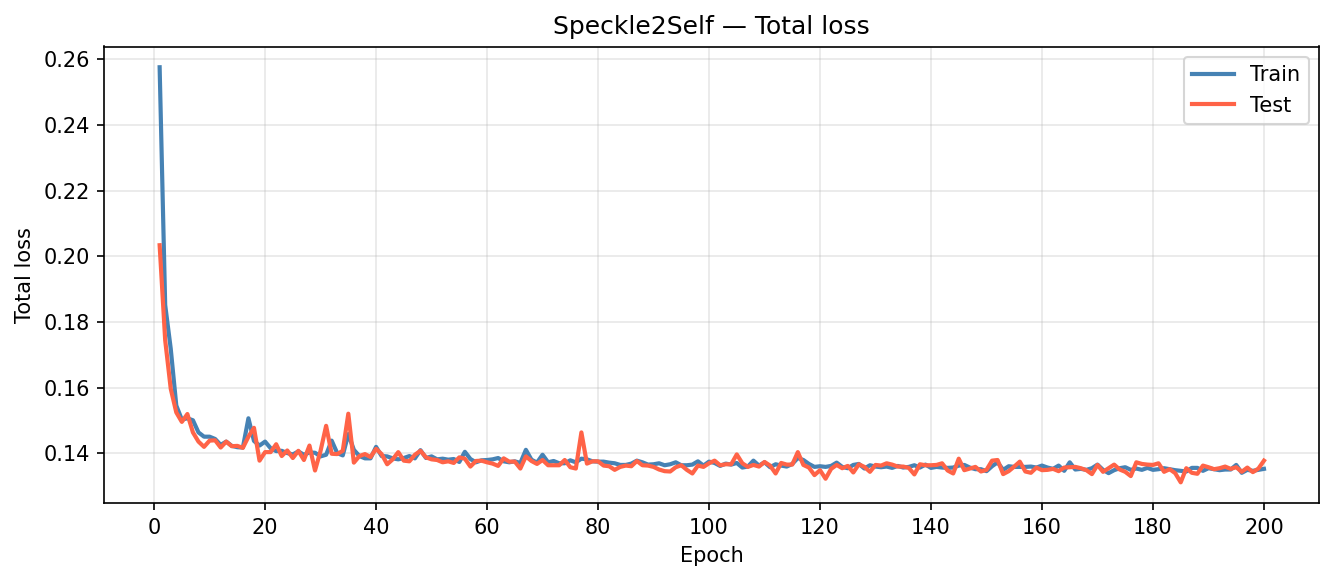

Saved → d:\graphs-n-tables\speckle2self\s2s_loss_total.png


In [17]:
# ── Total loss ────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(epochs, train_total, label='Train', color='steelblue', lw=2)
ax.plot(epochs, val_total,   label='Test',  color='tomato',    lw=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('Total loss')
ax.set_title('Speckle2Self — Total loss')
ax.legend()
ax.xaxis.set_major_locator(ticker.MultipleLocator(20))
ax.grid(True, alpha=0.3)
fig.tight_layout()
out = os.path.join(OUT_DIR, 's2s_loss_total.png')
fig.savefig(out, dpi=150, bbox_inches='tight')
plt.close(fig)
ipy_display(IPyImage(filename=out))
print(f'Saved → {out}')

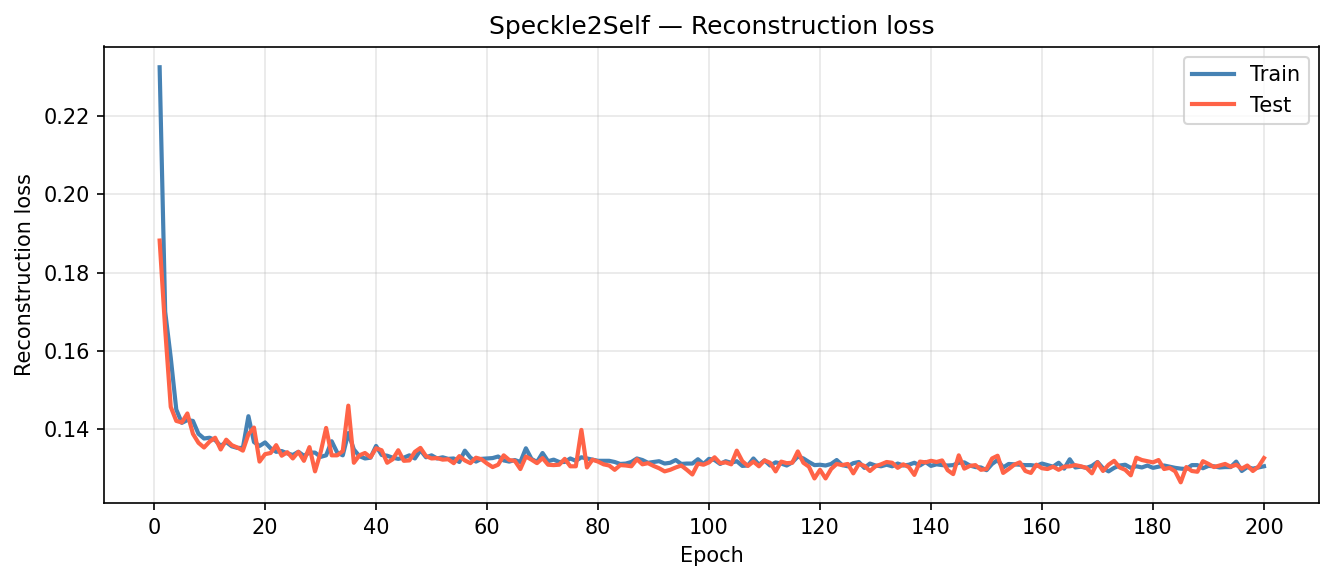

Saved → d:\graphs-n-tables\speckle2self\s2s_loss_rec.png


In [18]:
# ── Reconstruction loss ───────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(epochs, train_rec, label='Train', color='steelblue', lw=2)
ax.plot(epochs, val_rec,   label='Test',  color='tomato',    lw=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('Reconstruction loss')
ax.set_title('Speckle2Self — Reconstruction loss')
ax.legend()
ax.xaxis.set_major_locator(ticker.MultipleLocator(20))
ax.grid(True, alpha=0.3)
fig.tight_layout()
out = os.path.join(OUT_DIR, 's2s_loss_rec.png')
fig.savefig(out, dpi=150, bbox_inches='tight')
plt.close(fig)
ipy_display(IPyImage(filename=out))
print(f'Saved → {out}')

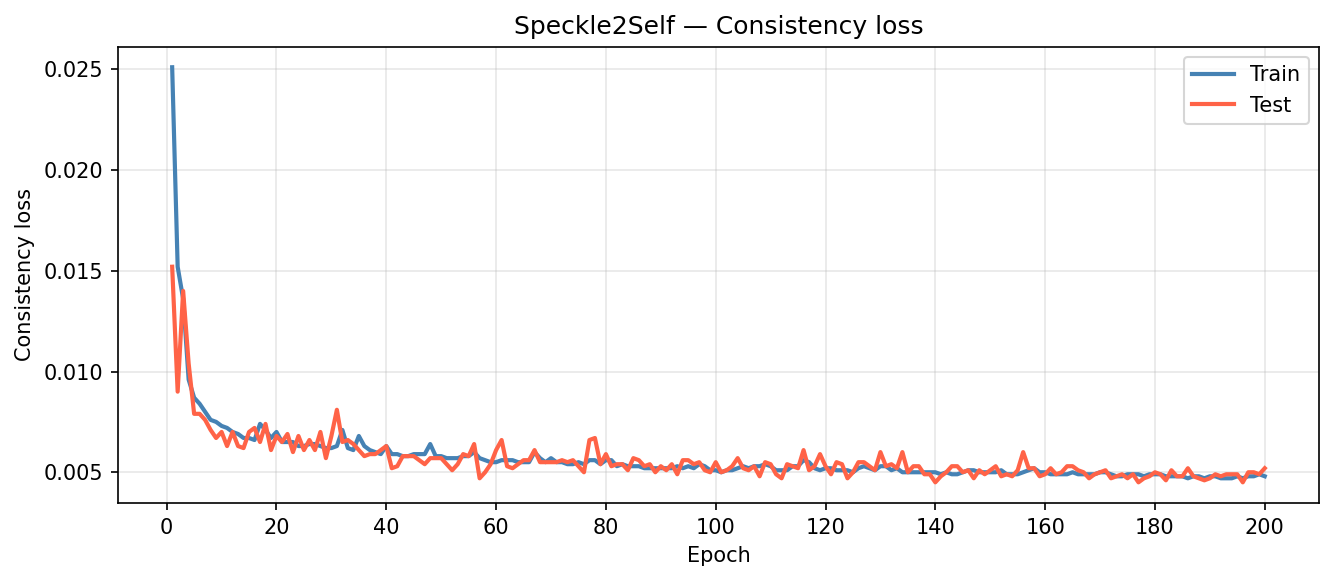

Saved → d:\graphs-n-tables\speckle2self\s2s_loss_consist.png


In [19]:
# ── Consistency loss ──────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(epochs, train_consist, label='Train', color='steelblue', lw=2)
ax.plot(epochs, val_consist,   label='Test',  color='tomato',    lw=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('Consistency loss')
ax.set_title('Speckle2Self — Consistency loss')
ax.legend()
ax.xaxis.set_major_locator(ticker.MultipleLocator(20))
ax.grid(True, alpha=0.3)
fig.tight_layout()
out = os.path.join(OUT_DIR, 's2s_loss_consist.png')
fig.savefig(out, dpi=150, bbox_inches='tight')
plt.close(fig)
ipy_display(IPyImage(filename=out))
print(f'Saved → {out}')

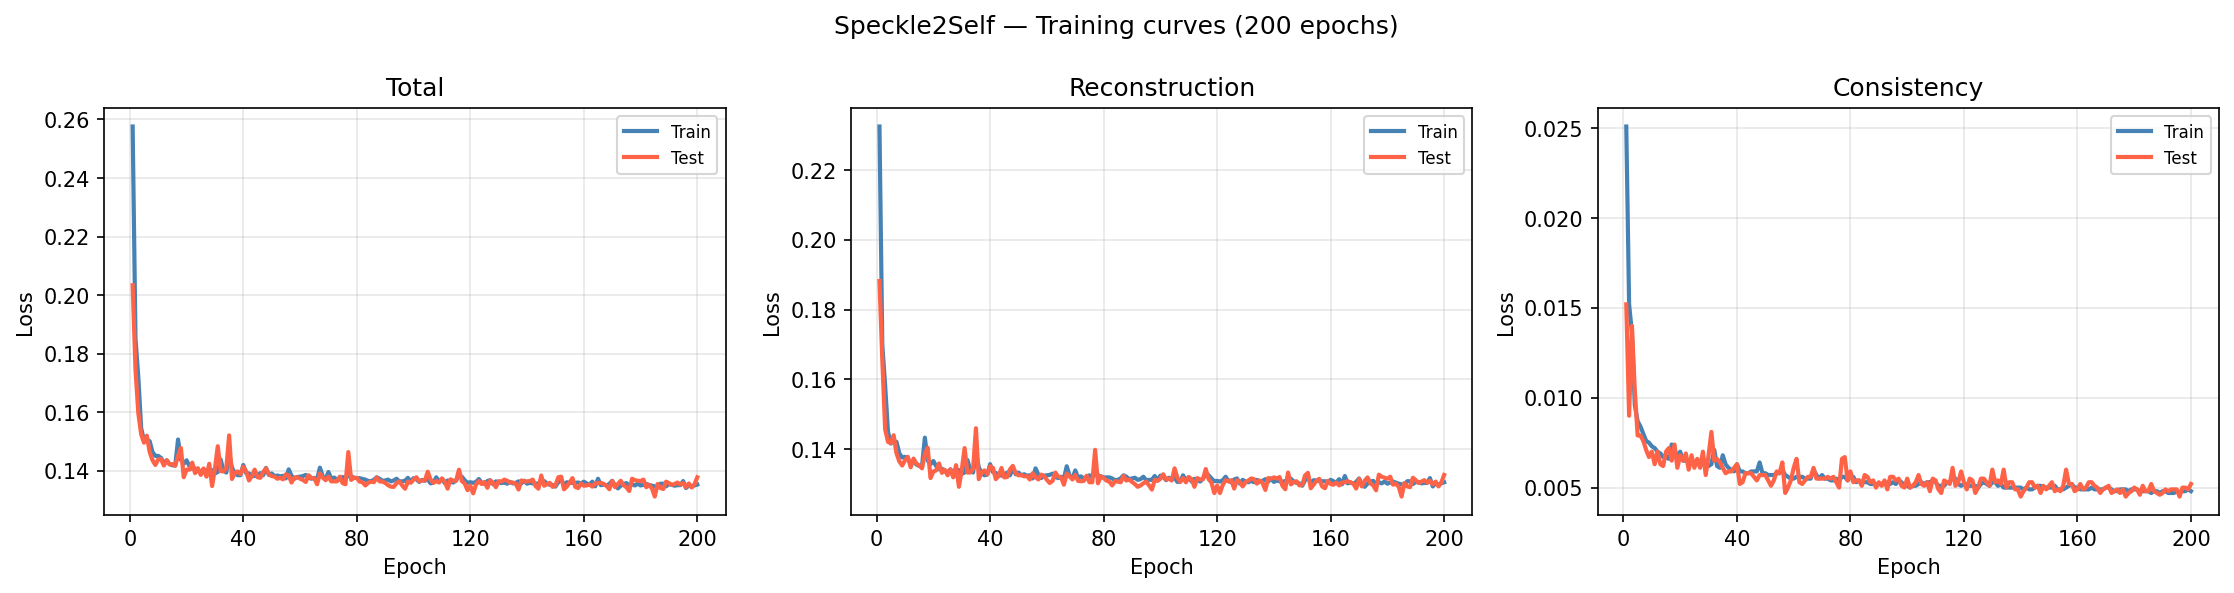

Saved → d:\graphs-n-tables\speckle2self\s2s_training_curves.png


In [20]:
# ── All three components in one figure ───────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (tr, vl, title, ylabel) in zip(axes, [
    (train_total,   val_total,   'Total',         'Loss'),
    (train_rec,     val_rec,     'Reconstruction','Loss'),
    (train_consist, val_consist, 'Consistency',   'Loss'),
]):
    ax.plot(epochs, tr, label='Train', color='steelblue', lw=2)
    ax.plot(epochs, vl, label='Test',  color='tomato',    lw=2)
    ax.set_xlabel('Epoch')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(40))
    ax.grid(True, alpha=0.3)

fig.suptitle('Speckle2Self — Training curves (200 epochs)', fontsize=12)
fig.tight_layout()
out = os.path.join(OUT_DIR, 's2s_training_curves.png')
fig.savefig(out, dpi=150, bbox_inches='tight')
plt.close(fig)
ipy_display(IPyImage(filename=out))
print(f'Saved → {out}')